# FLOPs de inferencia de SAN en GPU

Estima exclusivamente los FLOPs de inferencia de **SAN** sobre CROHME 2014 mediante `torch.profiler`. Este notebook no mide ni reporta latencia.

> Los FLOPs son una estimación para los operadores que reconoce PyTorch; no representan necesariamente todas las operaciones ejecutadas por el modelo.

In [1]:
from pathlib import Path
import gc, json, os, platform, sys
os.environ.setdefault('KINETO_LOG_LEVEL', '5')

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path.cwd() / '..', Path.cwd() / '../..']:
        candidate = candidate.resolve()
        if (candidate / 'SAN').is_dir() and (candidate / 'data').is_dir():
            return candidate
    raise FileNotFoundError('No se encontró la raíz con SAN/ y data/.')

ROOT = find_project_root()
SAN_ROOT = ROOT / 'SAN'
RESULTS_DIR = ROOT / 'Cascada' / '01_seleccion' / 'resultados'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda:0')
assert torch.cuda.is_available(), 'CUDA no está disponible.'
print('Raíz   :', ROOT)
print('GPU    :', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)

Raíz   : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas
GPU    : NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch: 2.0.1+cu118


## Carga del modelo y del checkpoint

In [2]:
sys.path.insert(0, str(SAN_ROOT))
from utils import load_config
from infer.Backbone import Backbone
from dataset import Words

params = load_config(SAN_ROOT / '14.yaml')
params['device'] = DEVICE
params['word_path'] = str(SAN_ROOT / 'data' / 'word.txt')
params['checkpoint'] = str(SAN_ROOT / 'checkpoints' / 'SAN_decoder' / 'best.pth')
words = Words(params['word_path'])
params['word_num'], params['struct_num'], params['words'] = len(words), 7, words
model = Backbone(params)
state = torch.load(params['checkpoint'], map_location='cpu', weights_only=True)
model.load_state_dict(state['model'])
model = model.to(DEVICE).eval().requires_grad_(False)
torch.cuda.synchronize()
print('Checkpoint:', params['checkpoint'])

try UTF-8 encoding
115 symbols in total


c:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\.venv-hmer-gpu\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Checkpoint: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\SAN\checkpoints\SAN_decoder\best.pth


In [3]:
def prepare_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(path)
    tensor = torch.from_numpy(image).float().div_(255).unsqueeze(0).unsqueeze(0)
    mask = torch.ones_like(tensor)
    return tensor.to(DEVICE), mask.to(DEVICE), image.shape

def estimate_flops(image, mask):
    with torch.profiler.profile(
        activities=[torch.profiler.ProfilerActivity.CPU],
        record_shapes=True,
        with_flops=True,
    ) as profiler:
        with torch.inference_mode():
            output = model(image, mask)
        torch.cuda.synchronize()
    estimated_flops = sum(event.flops or 0 for event in profiler.key_averages())
    del output
    return int(estimated_flops)

## Configuración y calentamiento

`MAX_SAMPLES = None` procesa toda la partición. El calentamiento se realiza sin perfilador y no forma parte de la estimación.

In [4]:
YEAR = '2014'
MAX_SAMPLES = None
WARMUP_RUNS = 3
PROGRESS_EVERY = 25

split_dir = ROOT / 'data' / 'Modelo1' / YEAR
image_dir = split_dir / '14_test_images'
samples = []
for line in (split_dir / 'test_caption.txt').read_text(encoding='utf-8').splitlines():
    parts = line.strip().split()
    if parts:
        sample_id = parts[0][:-4] if parts[0].endswith('.jpg') else parts[0]
        samples.append(sample_id)
if MAX_SAMPLES is not None:
    samples = samples[:MAX_SAMPLES]
if not samples:
    raise RuntimeError('No hay muestras para evaluar.')

print(f'Muestras seleccionadas: {len(samples)} | CROHME {YEAR}')
warm_image, warm_mask, _ = prepare_image(image_dir / f'{samples[0]}_0.bmp')
with torch.inference_mode():
    for _ in range(WARMUP_RUNS):
        warm_output = model(warm_image, warm_mask)
        torch.cuda.synchronize()
        del warm_output
del warm_image, warm_mask
gc.collect()
torch.cuda.synchronize()
print(f'Warm-up terminado: {WARMUP_RUNS} ejecuciones.')

Muestras seleccionadas: 986 | CROHME 2014
Warm-up terminado: 3 ejecuciones.


## Estimación de FLOPs

Se ejecuta una inferencia perfilada por imagen. No se utiliza ningún cronómetro.

In [5]:
rows = []
for index, sample_id in enumerate(samples, start=1):
    path = image_dir / f'{sample_id}_0.bmp'
    row = {
        'index': index, 'sample_id': sample_id, 'image_file': path.name,
        'status': 'ok', 'error': '',
    }
    try:
        image, mask, (height, width) = prepare_image(path)
        estimated_flops = estimate_flops(image, mask)
        row.update({
            'height': height, 'width': width,
            'estimated_flops': estimated_flops,
            'estimated_gflops': estimated_flops / 1e9,
        })
        del image, mask
    except Exception as exc:
        row.update({
            'status': 'error', 'error': f'{type(exc).__name__}: {exc}',
            'estimated_flops': np.nan, 'estimated_gflops': np.nan,
        })
        if 'out of memory' in str(exc).lower():
            rows.append(row)
            raise
    rows.append(row)
    gc.collect()
    if index == 1 or index % PROGRESS_EVERY == 0 or index == len(samples):
        valid_now = [item['estimated_gflops'] for item in rows if item['status'] == 'ok']
        print(f'{index:4d}/{len(samples)} | válidas={len(valid_now):4d} | GFLOPs media={np.mean(valid_now):.2f}')

   1/986 | válidas=   1 | GFLOPs media=10.32
  25/986 | válidas=  25 | GFLOPs media=8.31
  50/986 | válidas=  50 | GFLOPs media=10.90
  75/986 | válidas=  75 | GFLOPs media=9.77
 100/986 | válidas= 100 | GFLOPs media=9.67
 125/986 | válidas= 125 | GFLOPs media=9.27
 150/986 | válidas= 150 | GFLOPs media=9.24
 175/986 | válidas= 175 | GFLOPs media=9.35
 200/986 | válidas= 200 | GFLOPs media=9.83
 225/986 | válidas= 225 | GFLOPs media=9.34
 250/986 | válidas= 250 | GFLOPs media=9.15
 275/986 | válidas= 275 | GFLOPs media=9.05
 300/986 | válidas= 300 | GFLOPs media=8.75
 325/986 | válidas= 325 | GFLOPs media=8.59
 350/986 | válidas= 350 | GFLOPs media=9.25
 375/986 | válidas= 375 | GFLOPs media=9.59
 400/986 | válidas= 400 | GFLOPs media=9.90
 425/986 | válidas= 425 | GFLOPs media=10.82
 450/986 | válidas= 450 | GFLOPs media=10.76
 475/986 | válidas= 475 | GFLOPs media=10.53
 500/986 | válidas= 500 | GFLOPs media=10.44
 525/986 | válidas= 525 | GFLOPs media=10.34
 550/986 | válidas= 550 |

## Resumen y visualización

,valor
model,SAN
metric,estimated FLOPs
dataset,CROHME 2014
samples_requested,986
samples_valid,986
errors,0
estimated_flops_mean,9764814816.237322
estimated_flops_median,5795056985.5
estimated_flops_p95,29069249017.25
estimated_flops_p99,56525386110.89994


CSV    : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\benchmark_san_flops_crohme_2014.csv
Resumen: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\resumen_san_flops_crohme_2014.json


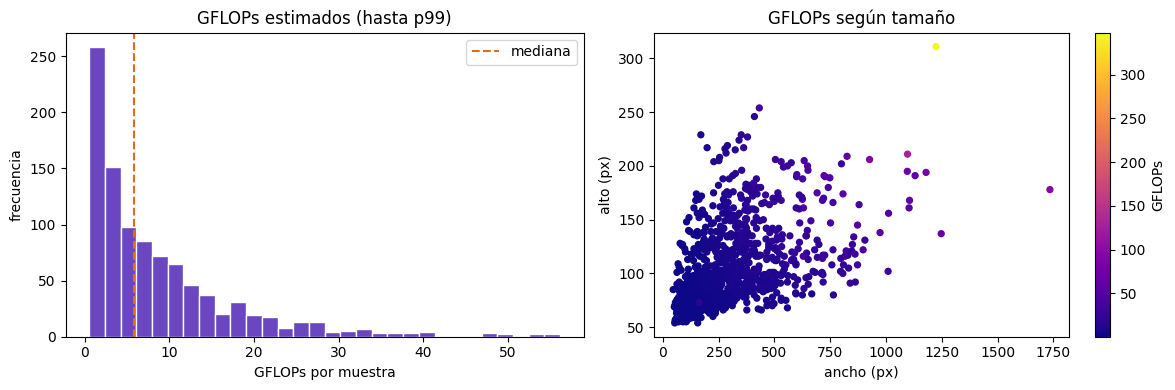

Gráfica: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\benchmark_san_flops_crohme_2014.png


In [6]:
results = pd.DataFrame(rows)
valid = results.loc[results['status'] == 'ok'].copy()
if valid.empty:
    raise RuntimeError('No hubo estimaciones válidas.')
flops = valid['estimated_flops'].to_numpy(dtype=np.float64)
summary = {
    'model': 'SAN',
    'metric': 'estimated FLOPs',
    'dataset': f'CROHME {YEAR}',
    'samples_requested': len(samples),
    'samples_valid': len(valid),
    'errors': int((results['status'] != 'ok').sum()),
    'estimated_flops_mean': float(np.mean(flops)),
    'estimated_flops_median': float(np.median(flops)),
    'estimated_flops_p95': float(np.percentile(flops, 95)),
    'estimated_flops_p99': float(np.percentile(flops, 99)),
    'estimated_flops_min': float(np.min(flops)),
    'estimated_flops_max': float(np.max(flops)),
    'estimated_gflops_mean': float(np.mean(flops) / 1e9),
    'estimated_gflops_median': float(np.median(flops) / 1e9),
    'estimated_gflops_p95': float(np.percentile(flops, 95) / 1e9),
    'estimated_gflops_p99': float(np.percentile(flops, 99) / 1e9),
    'estimated_gflops_min': float(np.min(flops) / 1e9),
    'estimated_gflops_max': float(np.max(flops) / 1e9),
    'estimated_total_tflops': float(np.sum(flops) / 1e12),
    'gpu': torch.cuda.get_device_name(0),
    'python': platform.python_version(),
    'pytorch': torch.__version__,
    'cuda': torch.version.cuda,
    'warmup_runs': WARMUP_RUNS,
    'flops_scope': 'Estimación de torch.profiler para los operadores soportados; una inferencia perfilada por imagen.',
}

csv_path = RESULTS_DIR / f'benchmark_san_flops_crohme_{YEAR}.csv'
json_path = RESULTS_DIR / f'resumen_san_flops_crohme_{YEAR}.json'
results.to_csv(csv_path, index=False, encoding='utf-8')
json_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([summary]).T.rename(columns={0: 'valor'}))
print('CSV    :', csv_path)
print('Resumen:', json_path)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
display_limit = np.percentile(valid['estimated_gflops'], 99)
axes[0].hist(valid.loc[valid['estimated_gflops'] <= display_limit, 'estimated_gflops'], bins=30, color='#6b46c1', edgecolor='white')
axes[0].axvline(summary['estimated_gflops_median'], color='#dd6b20', linestyle='--', label='mediana')
axes[0].set(title='GFLOPs estimados (hasta p99)', xlabel='GFLOPs por muestra', ylabel='frecuencia')
axes[0].legend()
scatter = axes[1].scatter(valid['width'], valid['height'], c=valid['estimated_gflops'], cmap='plasma', s=18)
axes[1].set(title='GFLOPs según tamaño', xlabel='ancho (px)', ylabel='alto (px)')
fig.colorbar(scatter, ax=axes[1], label='GFLOPs')
fig.tight_layout()
plot_path = RESULTS_DIR / f'benchmark_san_flops_crohme_{YEAR}.png'
fig.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.show()
print('Gráfica:', plot_path)

## Lectura de los resultados

- Cada muestra produce una única inferencia bajo `torch.profiler`.
- `with_flops=True` solo contabiliza los operadores para los que PyTorch implementa estimación de FLOPs.
- El total en TFLOPs es la suma de las estimaciones de las muestras, no una tasa por segundo.
- No se calcula ni reporta latencia, porque la instrumentación del perfilador altera el tiempo de ejecución.
- No se calcula exact match, CER ni VRAM.